# Imja Tsho Glacial Lake Expansion, 2018–2024

Imja Tsho is a moraine-dammed glacial lake in Sagarmatha National Park, Nepal, fed by the retreating Imja Glacier. As the glacier retreats the lake grows, and with it the volume of water that a Glacial Lake Outburst Flood (GLOF) could release. This notebook measures the lake's open-water surface area on three dates using Sentinel-2 imagery and quantifies how it changed.

**Data.** Sentinel-2 Level-2A surface reflectance from the Copernicus Data Space Ecosystem, acquired on 30 October 2018, 8 November 2021 and 13 October 2024. Bands B02, B03, B04 (visible), B08 (near-infrared) and B11 (shortwave-infrared) on a 10 m grid. See `data/README.md` for download instructions.

**Method.** Water is detected with the Modified Normalized Difference Water Index (MNDWI, green vs. SWIR), thresholded automatically with Otsu's method. Because snow and ice score as high on MNDWI as water does, pixels that are bright in the near-infrared are rejected, and a standard NDWI > 0 test removes remaining non-water pixels. Connected-component labelling then keeps the single largest contiguous water body: Imja Tsho. Its area is the pixel count multiplied by the 100 m² pixel area.

## 1. Setup

The processing steps live in the `glacial_lake` package (`src/glacial_lake/`); this notebook calls them and discusses the results. `scripts/run_analysis.py` runs the same pipeline and saves every figure to `figures/`.

| Function | Module | Returns |
| :--- | :--- | :--- |
| `load_scene(date, data_dir)` | `io` | `Scene`: surface-reflectance bands in [0, 1], geotransform, CRS and pixel area. |
| `ndwi(bands)`, `mndwi(bands)` | `indices` | Normalised-difference index arrays bounded to [-1, 1]. |
| `water_mask(mndwi, ndwi, nir)` | `segmentation` | Boolean open-water mask and the MNDWI Otsu threshold. |
| `largest_component(mask)` | `segmentation` | Mask of the single largest 8-connected water body. |
| `detect_lake(scene)` | `pipeline` | `LakeDetection` bundling all of the above, the lake area in km² and the snow/ice mask. |
| `area_km2`, `shape_descriptors`, `containment`, `boundary_uncertainty_km2`, `area_changes` | `metrics` | Area, extent, nesting between years, shoreline uncertainty and changes between dates. |

In [1]:
%config InlineBackend.figure_formats = ["jpeg"]
%config InlineBackend.print_figure_kwargs = {"bbox_inches": "tight", "pil_kwargs": {"quality": 85}}

import os
from pathlib import Path

import numpy as np
from skimage.filters import threshold_otsu
from skimage.measure import perimeter

from glacial_lake import metrics, plotting
from glacial_lake.config import ACQUISITION_DATES, LAKE_NAME
from glacial_lake.io import load_scene
from glacial_lake.pipeline import detect_lake
from glacial_lake.segmentation import NIR_CEILING, label_components

# The notebook runs from notebooks/. Set GLACIAL_LAKE_DATA_DIR to read the data elsewhere.
DATA_DIR = Path(os.environ.get("GLACIAL_LAKE_DATA_DIR", Path.cwd().parent / "data"))
target_years = list(ACQUISITION_DATES)

## 2. Data

Each band is read as a 16-bit digital number and divided by 10 000 to obtain surface reflectance. All bands share the same 10 m UTM grid (B11 is natively 20 m and was resampled by nearest neighbour at download time).

In [2]:
scenes = {year: load_scene(date, DATA_DIR) for year, date in ACQUISITION_DATES.items()}

for year, scene in scenes.items():
    b03 = scene.bands["B03"]
    print(
        f"{year} ({scene.date}): {scene.shape[0]}x{scene.shape[1]} px, "
        f"pixel {scene.pixel_size_m[0]:.0f} x {scene.pixel_size_m[1]:.0f} m, "
        f"B03 median reflectance {np.median(b03):.3f}"
    )

2018 (2018-10-30): 622x795 px, pixel 10 x 10 m, B03 median reflectance 0.192
2021 (2021-11-08): 622x795 px, pixel 10 x 10 m, B03 median reflectance 0.311
2024 (2024-10-13): 622x795 px, pixel 10 x 10 m, B03 median reflectance 0.301


### False-colour composites

A false-colour composite maps the near-infrared (B08) to red, red (B04) to green and green (B03) to blue. Each composite is contrast-stretched between its 2nd and 98th percentiles. This combination separates the main surfaces in the scene:

1. **Lake water.** Water absorbs near-infrared almost completely, so clear water appears black. Imja Tsho carries suspended glacial rock flour that raises its visible reflectance, so the lake appears dark blue-teal instead.
2. **Snow and ice.** Highly reflective in the visible and still bright in the near-infrared, rendered in white to pale cyan.
3. **Rock, moraine and debris-covered ice.** Similar reflectance across visible and near-infrared, rendered in neutral browns and greys.

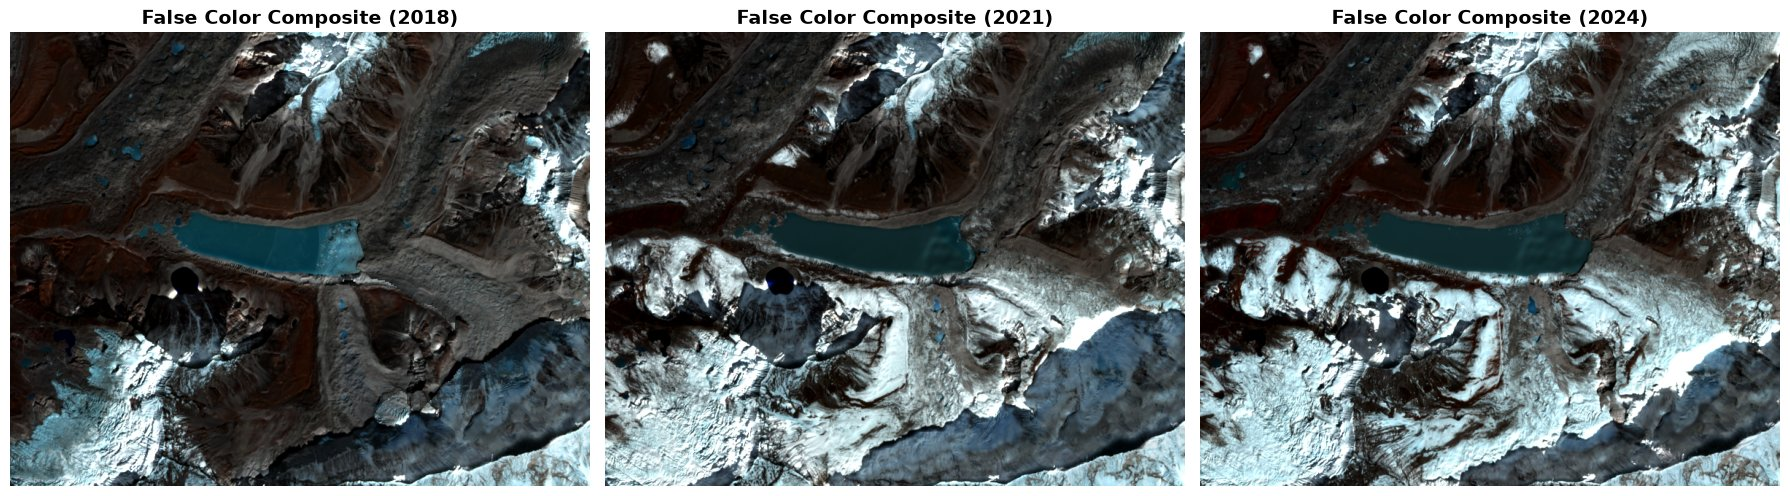

In [3]:
fig = plotting.plot_false_color_composites(scenes)

## 3. Spectral water indices

Both indices are normalised differences, bounded to [-1, 1].

**MNDWI, the primary detector.** `(Green − SWIR) / (Green + SWIR)` using B03 and B11 (Xu, 2006). Liquid water absorbs shortwave-infrared strongly regardless of how much sediment it carries, so MNDWI gives the turbid lake a strong, unambiguous signal.

**NDWI, a secondary filter.** `(Green − NIR) / (Green + NIR)` using B03 and B08 (McFeeters, 1996). Suspended sediment raises the lake's near-infrared reflectance and weakens its NDWI, which is why NDWI is not used as the primary detector here. It is still positive over the lake, so `NDWI > 0` is used as a confirmation test.

**The snow problem.** The MNDWI formula is identical to the Normalized Difference Snow Index (NDSI; Hall et al., 1995). Snow and ice therefore score as high on MNDWI as water does. What separates them is near-infrared brightness: water absorbs NIR, while snow and ice reflect it strongly. Pixels with B08 reflectance of `NIR_CEILING` (0.20) or more are therefore rejected. Without this test, the snowfields south of the lake merge with it into a single component several times the lake's size.

In [4]:
detections = {year: detect_lake(scene) for year, scene in scenes.items()}

for year, det in detections.items():
    lake = det.lake_mask
    nir = det.scene.bands["B08"]
    rejected = det.snow_ice_mask
    print(
        f"{year}: lake median MNDWI {np.median(det.mndwi[lake]):.2f}, "
        f"NDWI {np.median(det.ndwi[lake]):.2f}, NIR {np.median(nir[lake]):.3f} | "
        f"above the MNDWI threshold but rejected as snow/ice: "
        f"{rejected.sum() * det.scene.pixel_area_m2 / 1e6:.1f} km²"
    )

2018: lake median MNDWI 0.93, NDWI 0.54, NIR 0.082 | above the MNDWI threshold but rejected as snow/ice: 10.0 km²
2021: lake median MNDWI 0.94, NDWI 0.28, NIR 0.122 | above the MNDWI threshold but rejected as snow/ice: 24.5 km²
2024: lake median MNDWI 0.97, NDWI 0.31, NIR 0.121 | above the MNDWI threshold but rejected as snow/ice: 23.7 km²


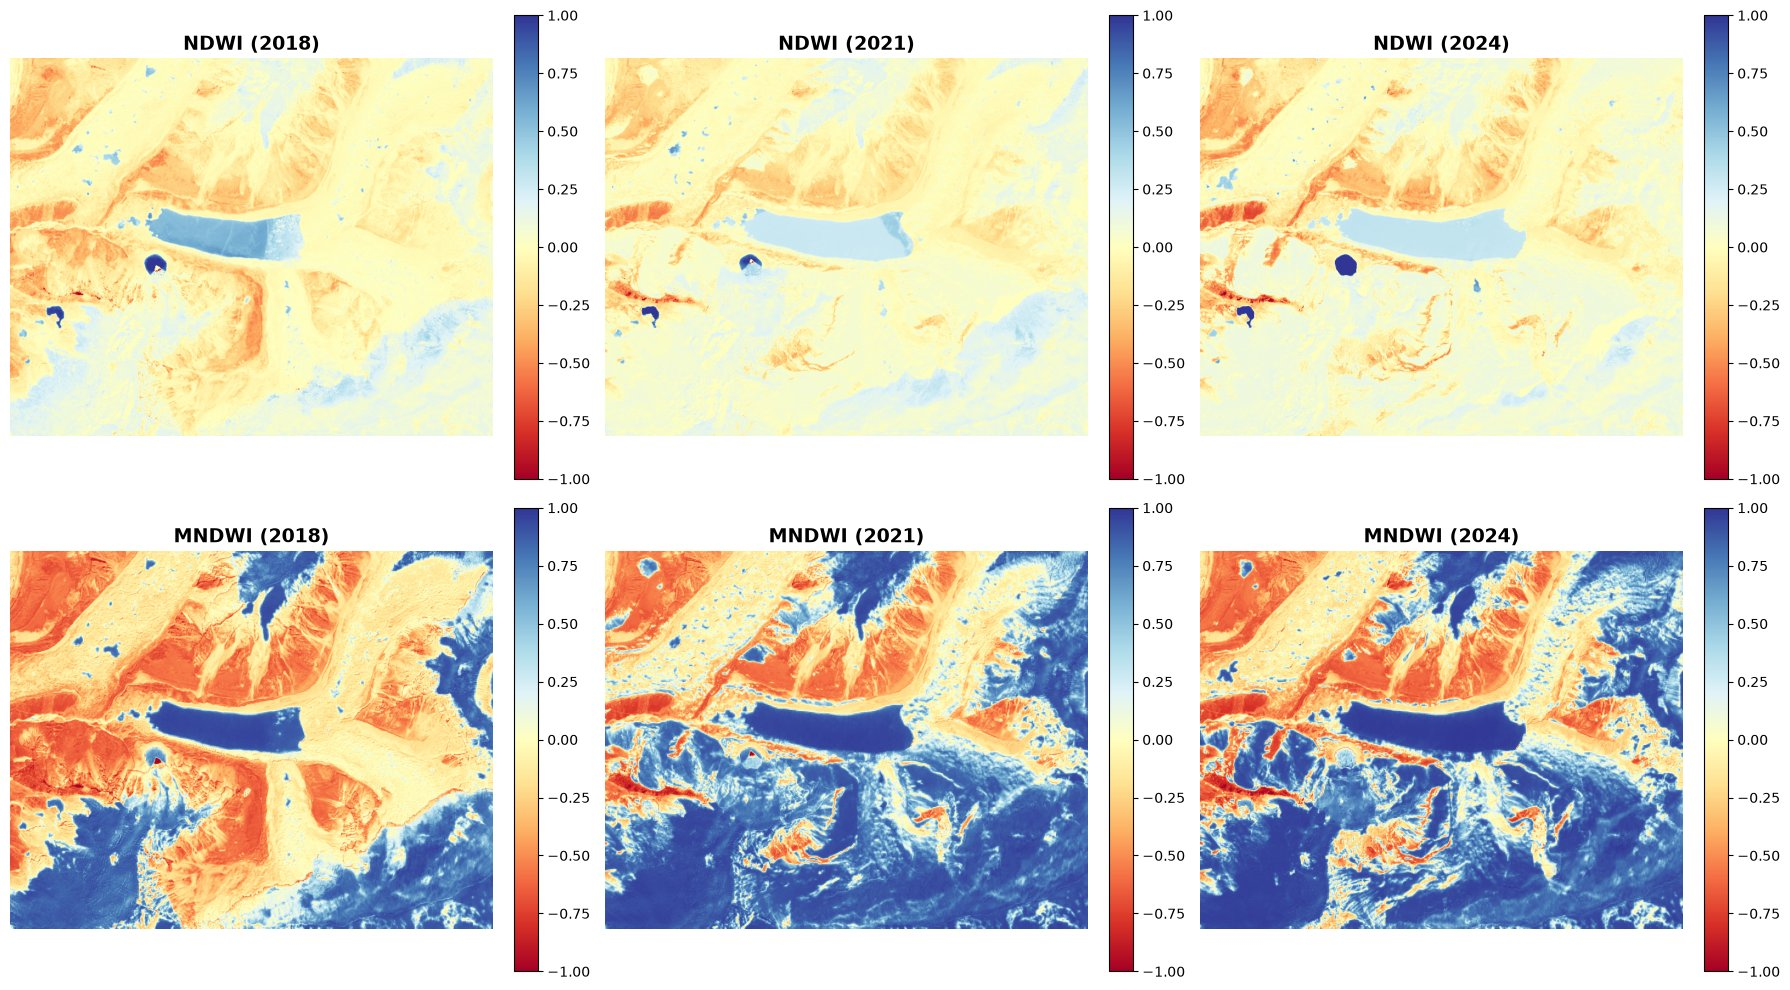

In [5]:
fig = plotting.plot_index_maps(detections)

### Why not threshold NDWI directly?

Otsu's method needs a bimodal distribution, with the threshold falling in the valley between two modes. The NDWI histograms below show that this condition is not met. The lake forms only a small, narrow peak (around 0.53 in 2018 and 0.27–0.31 in 2021 and 2024), dwarfed by the broad distribution of snow, ice and terrain around 0–0.1. The peak's position also shifts between dates, so no single NDWI threshold carries over from one year to the next. Otsu's method applied to NDWI lands near zero on every date (0.03, −0.02 and −0.10), which would classify most of the snow cover as water.

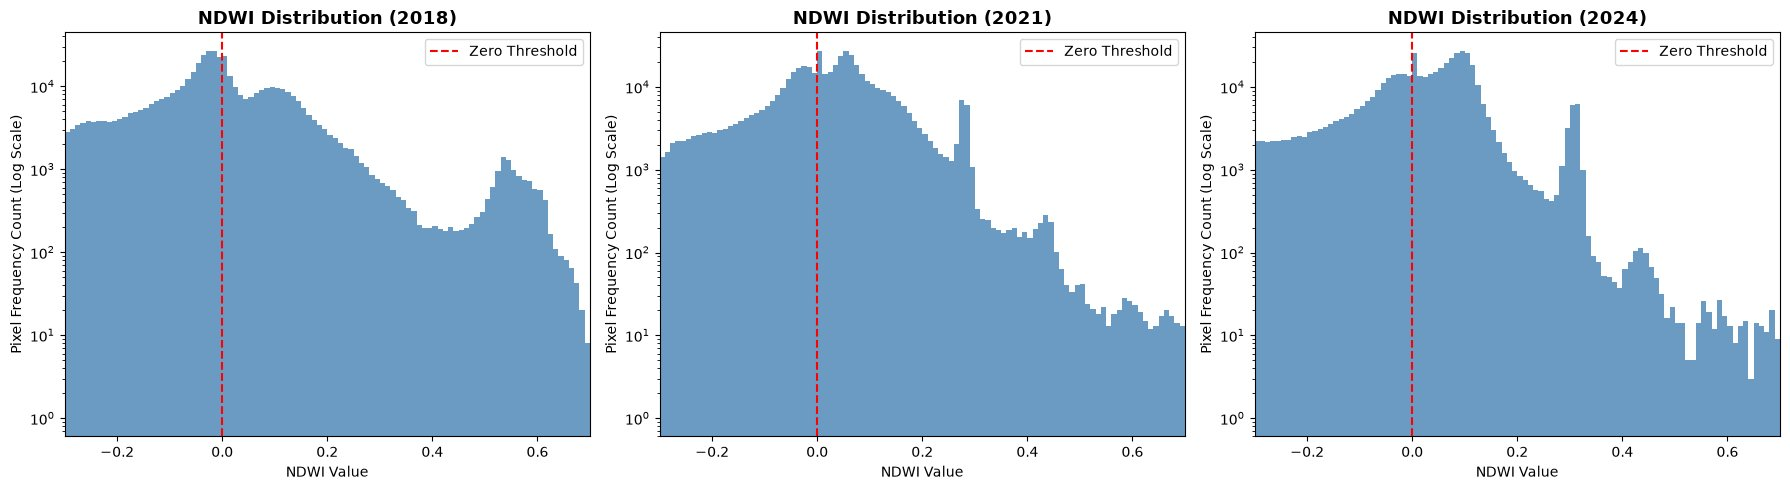

In [6]:
fig = plotting.plot_index_histograms(detections, "NDWI", xlim=(-0.3, 0.7))

## 4. Water segmentation and lake area

For each date the open-water mask is `MNDWI > Otsu threshold & NDWI > 0 & B08 < 0.20`. This mask still contains hundreds of small, disconnected water-like patches across the scene: shadowed snow, small ponds and wet ground. **Connected-component labelling** groups touching pixels (8-connectivity) into separate bodies, and only the largest one, Imja Tsho, is kept and measured.

The `NDWI > 0` test removes only a few hundred scattered pixels per date and has almost no effect on the lake itself. Pixels without data (zero in every band) are left out of both the Otsu histogram and the mask; these three scenes have none.

In [7]:
areas = {year: det.area_km2 for year, det in detections.items()}

header = ("Year", "MNDWI Otsu", "Water px", "Components", "Lake px", "Area (km²)")
print(" | ".join(f"{h:>10}" for h in header))
print("-" * 70)
for year, det in detections.items():
    _, sizes = label_components(det.water_mask)
    row = (
        f"{year:>10}",
        f"{det.otsu_threshold:>10.4f}",
        f"{int(det.water_mask.sum()):>10}",
        f"{int(np.count_nonzero(sizes)):>10}",
        f"{int(det.lake_mask.sum()):>10}",
        f"{det.area_km2:>10.3f}",
    )
    print(" | ".join(row))

print()
for change in metrics.area_changes(areas):
    print(f"{change.start}–{change.end}: {change.absolute_km2:+.3f} km² ({change.percent:+.2f}%)")
cagr = metrics.compound_annual_growth_rate(areas, ACQUISITION_DATES)
print(f"Compound annual growth rate: {cagr:.2%} (over the actual acquisition dates)")

      Year | MNDWI Otsu |   Water px | Components |    Lake px | Area (km²)
----------------------------------------------------------------------
      2018 |     0.2275 |      37861 |       1043 |      11785 |      1.179
      2021 |     0.2695 |      34261 |        980 |      15715 |      1.571
      2024 |     0.2517 |      31505 |        778 |      17921 |      1.792

2018–2021: +0.393 km² (+33.35%)
2021–2024: +0.221 km² (+14.04%)
2018–2024: +0.614 km² (+52.07%)
Compound annual growth rate: 7.29% (over the actual acquisition dates)


### Results overview

The grid places the true- and false-colour images next to the MNDWI map and the final lake mask. The green line on the MNDWI panels is the Otsu threshold contour. Many of the regions it encloses outside the lake are snow and ice, which pass the MNDWI threshold but are removed by the NIR test. The rest are small disconnected patches dropped by the largest-component step.

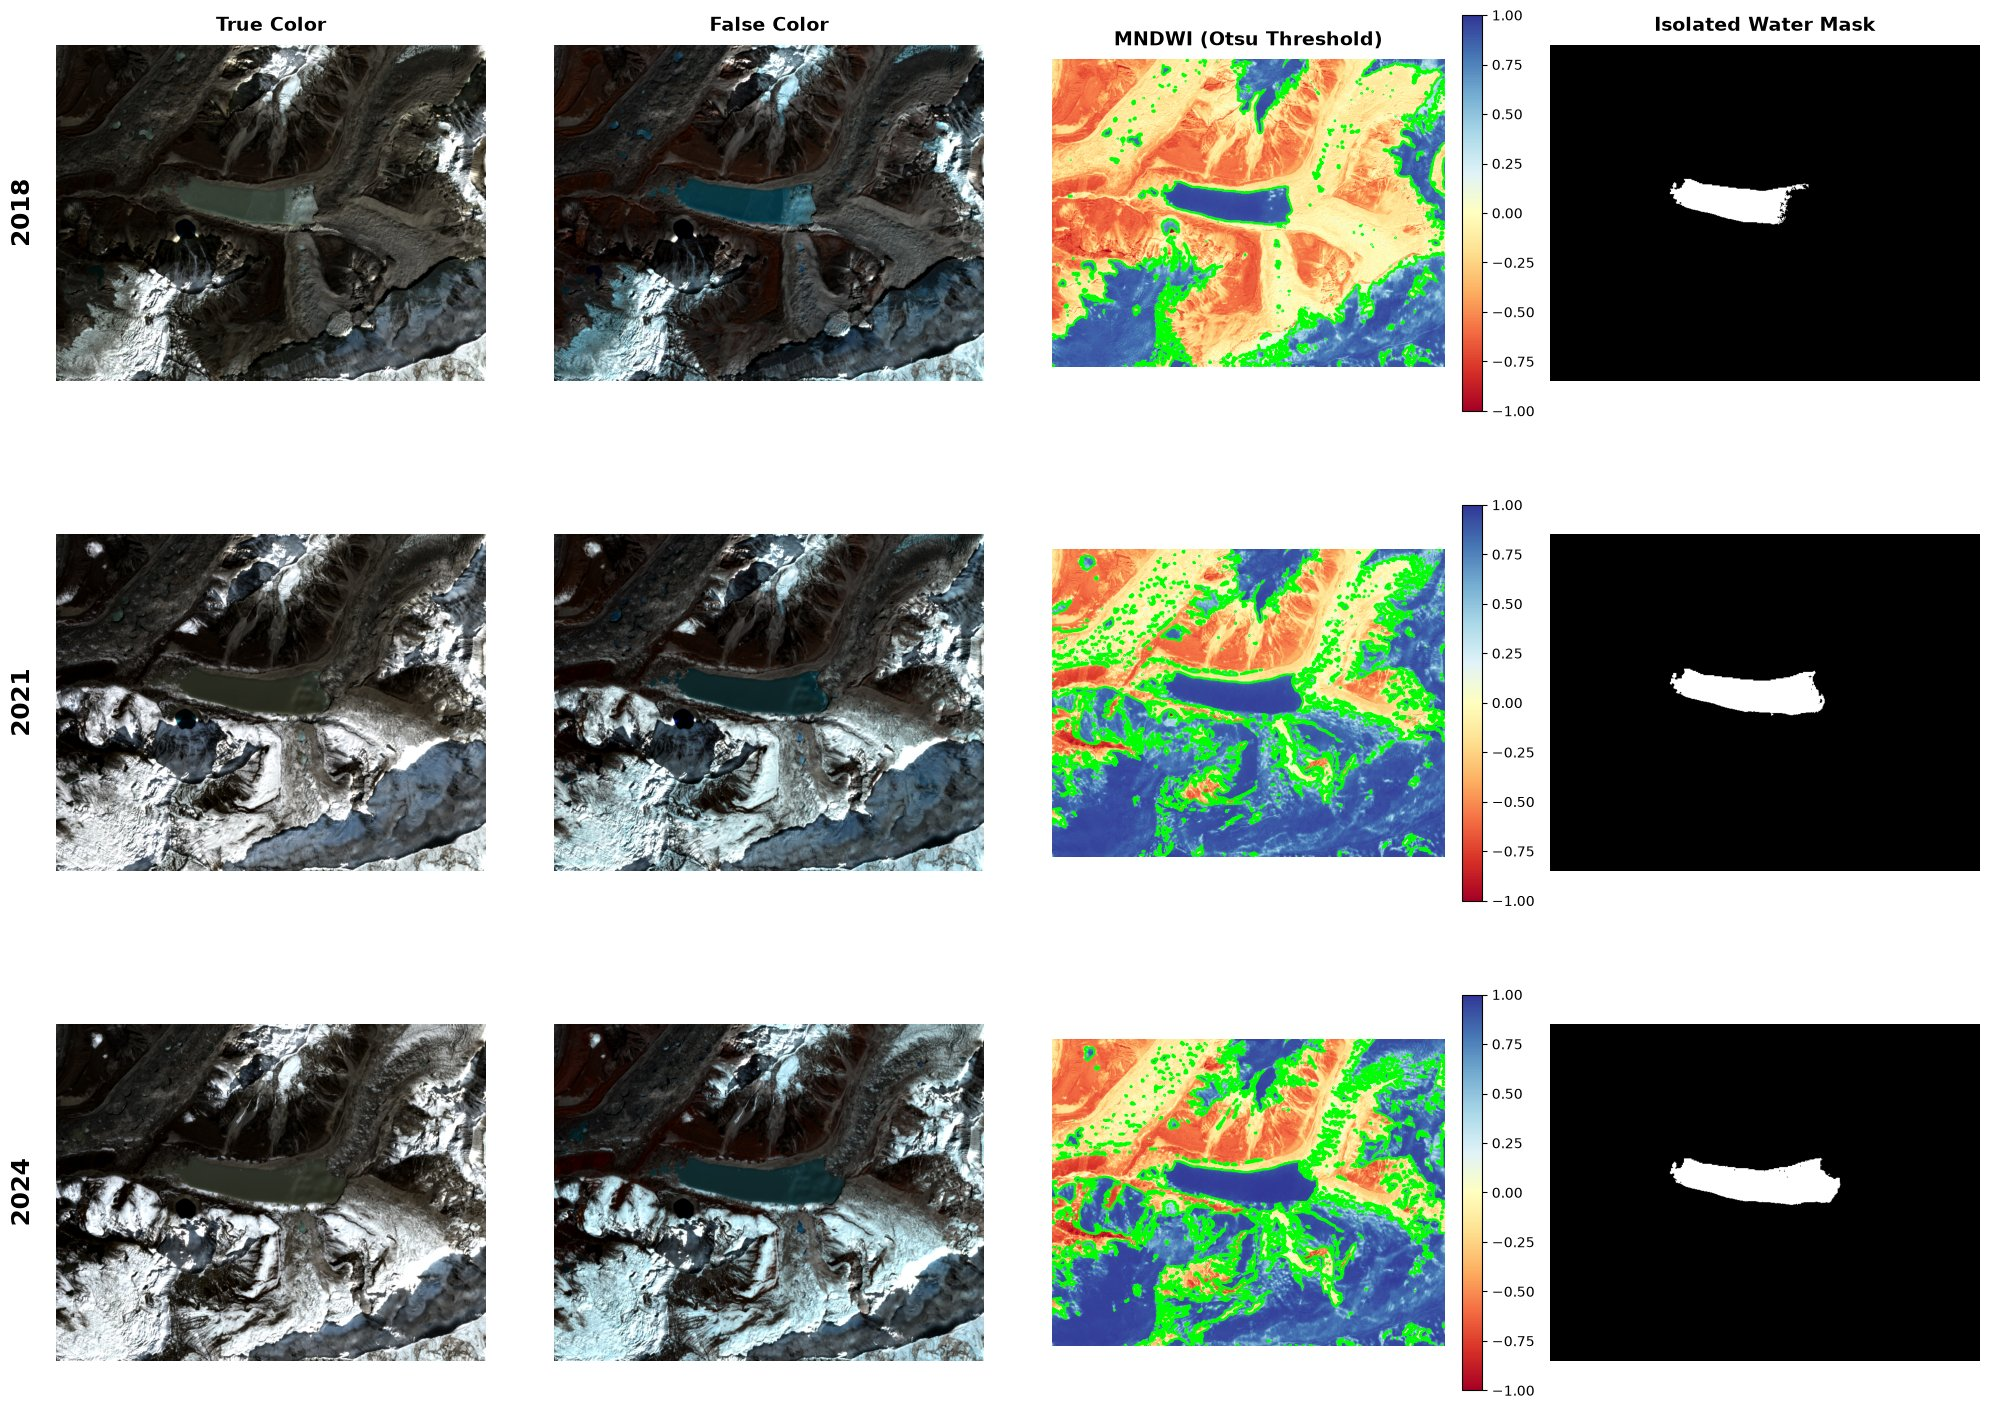

In [8]:
fig = plotting.plot_results_grid(detections)

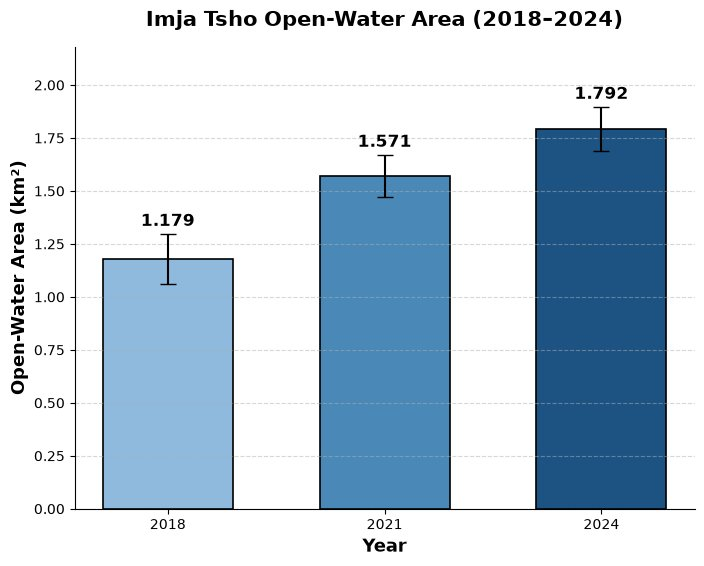

In [9]:
uncertainties = {
    year: metrics.boundary_uncertainty_km2(det.lake_mask, det.scene.pixel_area_m2)
    for year, det in detections.items()
}
fig = plotting.plot_area_bars(areas, uncertainties, lake_name=LAKE_NAME)

### Checking the Otsu assumption on MNDWI

Unlike NDWI, the MNDWI histograms are clearly bimodal: a land mode around −0.12 and a high mode around 0.9. The Otsu threshold (0.23–0.27) falls in the valley between them on every date. The high mode contains both water and snow/ice, which is why Otsu's method alone is not enough and the NIR test from Section 3 is needed.

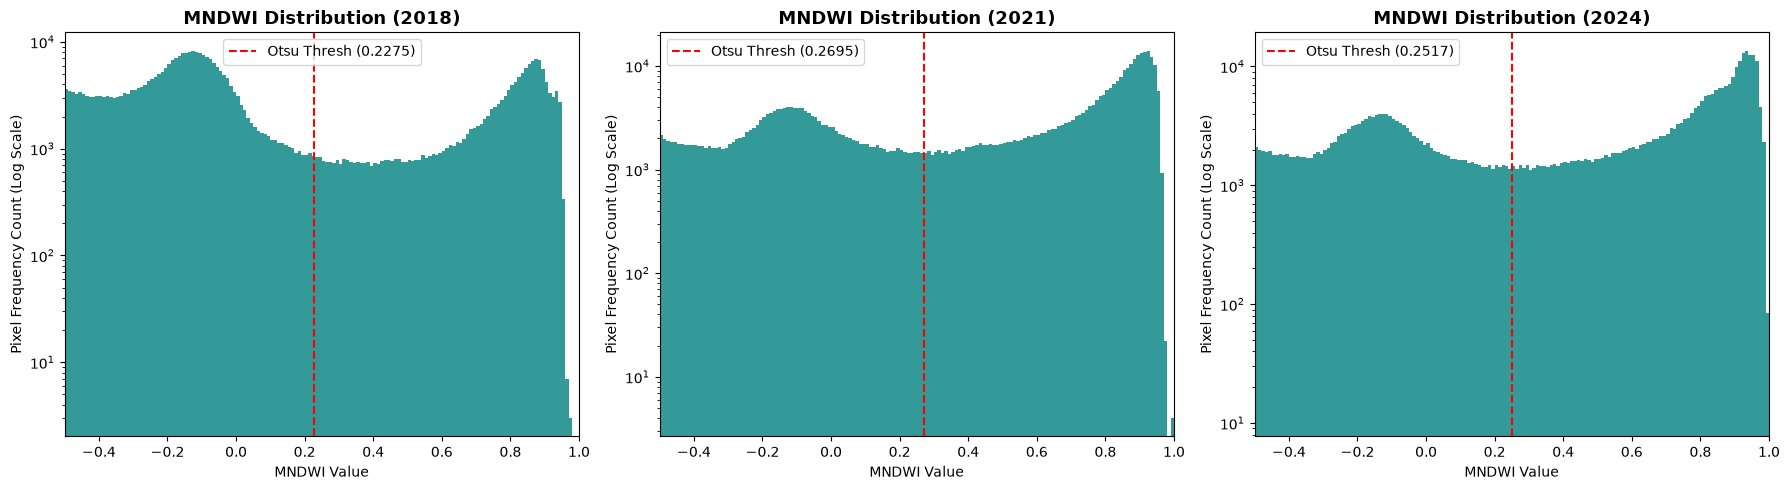

In [10]:
fig = plotting.plot_index_histograms(
    detections, "MNDWI", xlim=(-0.5, 1.0), show_otsu=True, color="teal"
)

## 5. Validation

### Is it the same lake every year?

Selecting "the largest component" could in principle pick a different object on different dates. Two checks address this:

- **Nesting.** If the lake only grows, nearly all of each earlier outline should lie inside the later one. This is a consistency check rather than a proof, since any growing shape passes it.
- **Where the change happens.** Imja Tsho is dammed by a terminal moraine at its western end and grows eastward as Imja Glacier retreats. The western end should stay fixed, nearly all of the gained pixels should lie in the eastern half, and the eastern shore should advance.

Because the growth happens at one end, the centroid is *expected* to move east by up to a few hundred metres. A centroid-stability test would wrongly flag this as an error.

In [11]:
shapes = {
    year: metrics.shape_descriptors(det.lake_mask, det.scene.pixel_size_m)
    for year, det in detections.items()
}
pixel_width = scenes[target_years[0]].pixel_size_m[0]

print("Shoreline extent (column of westernmost / easternmost lake pixel):")
for year, shape in shapes.items():
    west, east = shape.col_range
    print(
        f"  {year}: west {west}, east {east} -> length {(east - west + 1) * pixel_width:.0f} m, "
        f"aspect ratio {shape.aspect_ratio:.2f}"
    )

print("\nNesting (share of the earlier lake inside the later lake):")
consecutive = list(zip(target_years, target_years[1:], strict=False))
for earlier, later in [*consecutive, (target_years[0], target_years[-1])]:
    share = metrics.containment(detections[earlier].lake_mask, detections[later].lake_mask)
    print(f"  {earlier} inside {later}: {share:.1%}")

print("\nPixels gained and lost between dates, by half of the earlier lake:")
for earlier, later in consecutive:
    west, east = shapes[earlier].col_range
    in_west = np.arange(scenes[earlier].shape[1]) < (west + east) / 2
    gained = detections[later].lake_mask & ~detections[earlier].lake_mask
    lost = detections[earlier].lake_mask & ~detections[later].lake_mask
    print(
        f"  {earlier}–{later}: gained {gained.sum()} px ({gained[:, in_west].sum()} in the "
        f"western half), lost {lost.sum()} px ({lost[:, in_west].sum()} in the western half)"
    )

print("\nEastern shoreline advance:")
for earlier, later in consecutive:
    advance = (shapes[later].col_range[1] - shapes[earlier].col_range[1]) * pixel_width
    print(f"  {earlier}–{later}: {advance:+.0f} m")

Shoreline extent (column of westernmost / easternmost lake pixel):
  2018: west 222, east 477 -> length 2560 m, aspect ratio 3.05
  2021: west 222, east 507 -> length 2860 m, aspect ratio 3.29
  2024: west 222, east 536 -> length 3150 m, aspect ratio 3.62

Nesting (share of the earlier lake inside the later lake):
  2018 inside 2021: 96.7%
  2021 inside 2024: 99.6%
  2018 inside 2024: 98.2%

Pixels gained and lost between dates, by half of the earlier lake:
  2018–2021: gained 4314 px (17 in the western half), lost 384 px (215 in the western half)
  2021–2024: gained 2268 px (175 in the western half), lost 62 px (20 in the western half)

Eastern shoreline advance:
  2018–2021: +300 m
  2021–2024: +290 m


The westernmost lake pixel, at the outlet, sits on the same column on all three dates. Only 17 of the 4314 pixels gained between 2018 and 2021, and 175 of the 2268 gained between 2021 and 2024, lie in the western half, and the losses are an order of magnitude smaller than the gains. The eastern shore advances by about 300 m in each interval, and over 96% of each earlier outline lies within the later one. The algorithm tracked the same lake throughout, and the lake grew at its glacier end.

### Shoreline evolution

Overlaying the three outlines on the 2024 true-colour image shows the same pattern, and the zoomed view shows how closely the mask follows the visible shoreline.

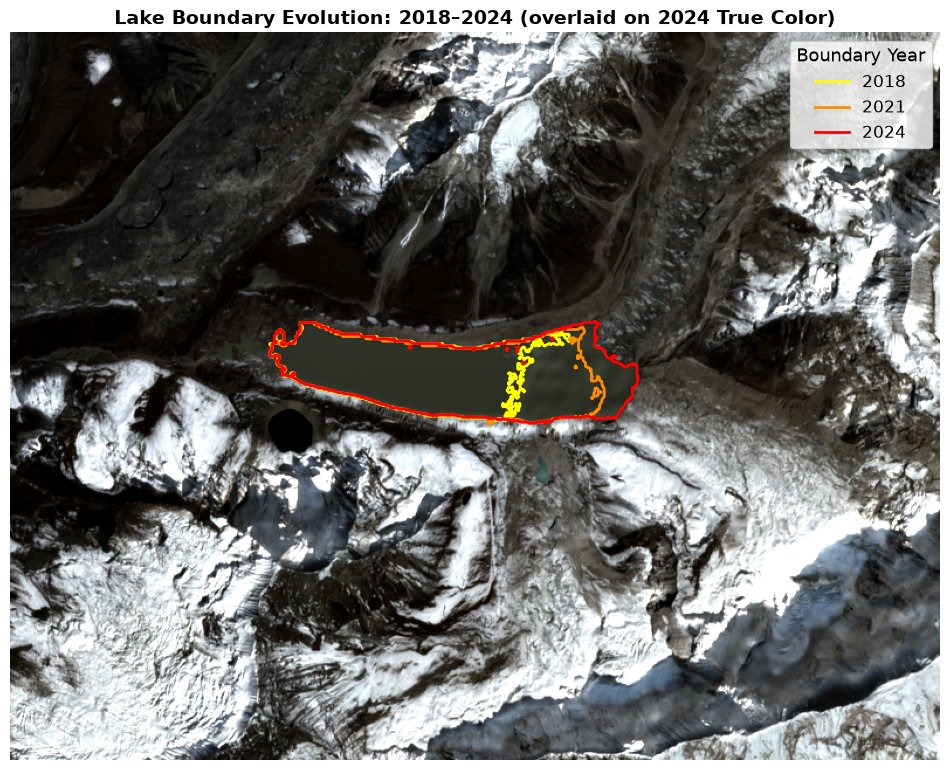

In [12]:
fig = plotting.plot_boundary_evolution(detections)

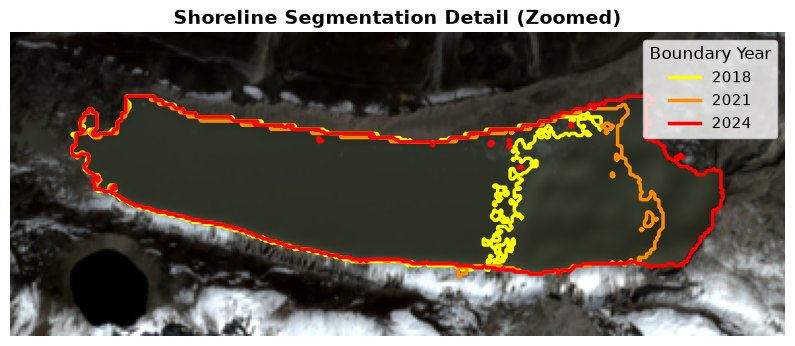

In [13]:
fig = plotting.plot_boundary_evolution(detections, zoom_padding=30)

### Was the lake split into pieces?

If floating ice or a shadow had cut the lake into separate bodies on some date, the largest-component step would keep only one piece and underestimate the area. The test is therefore not "are there other large components?" There always are, mostly snow and shadow patches far from the lake. The question is whether any sizeable water component lies **right next to** the lake. The cell below lists every other component within 30 m (straight-line distance) of the lake outline.

In [14]:
NEAR_DISTANCE_PX = 3  # 30 m

for year, det in detections.items():
    nearby = metrics.nearby_component_sizes(det.water_mask, det.lake_mask, NEAR_DISTANCE_PX)
    nearby_km2 = nearby * det.scene.pixel_area_m2 / 1e6
    largest = nearby_km2[0] if nearby.size else 0.0
    print(
        f"{year}: {nearby.size} components within {NEAR_DISTANCE_PX * pixel_width:.0f} m, "
        f"total {nearby_km2.sum():.4f} km², largest {largest:.4f} km² "
        f"({largest / det.area_km2:.2%} of the lake)"
    )

2018: 7 components within 30 m, total 0.0076 km², largest 0.0024 km² (0.20% of the lake)
2021: 7 components within 30 m, total 0.0028 km², largest 0.0008 km² (0.05% of the lake)
2024: 5 components within 30 m, total 0.0005 km², largest 0.0001 km² (0.01% of the lake)


The components bordering the lake are tiny: at most 0.0024 km², well under 1% of the lake area. The lake was not fragmented on any date. Just beyond the 30 m radius, a patch of about 0.02 km² lies 70–90 m west of the lake's outlet on all three dates. Because it is in the same place every time, it is a separate water body rather than a broken-off piece of the lake.

The figure below shows the pre-isolation masks for every date. The second- and third-largest components lie elsewhere in the scene, 0.5–3 km from the lake.

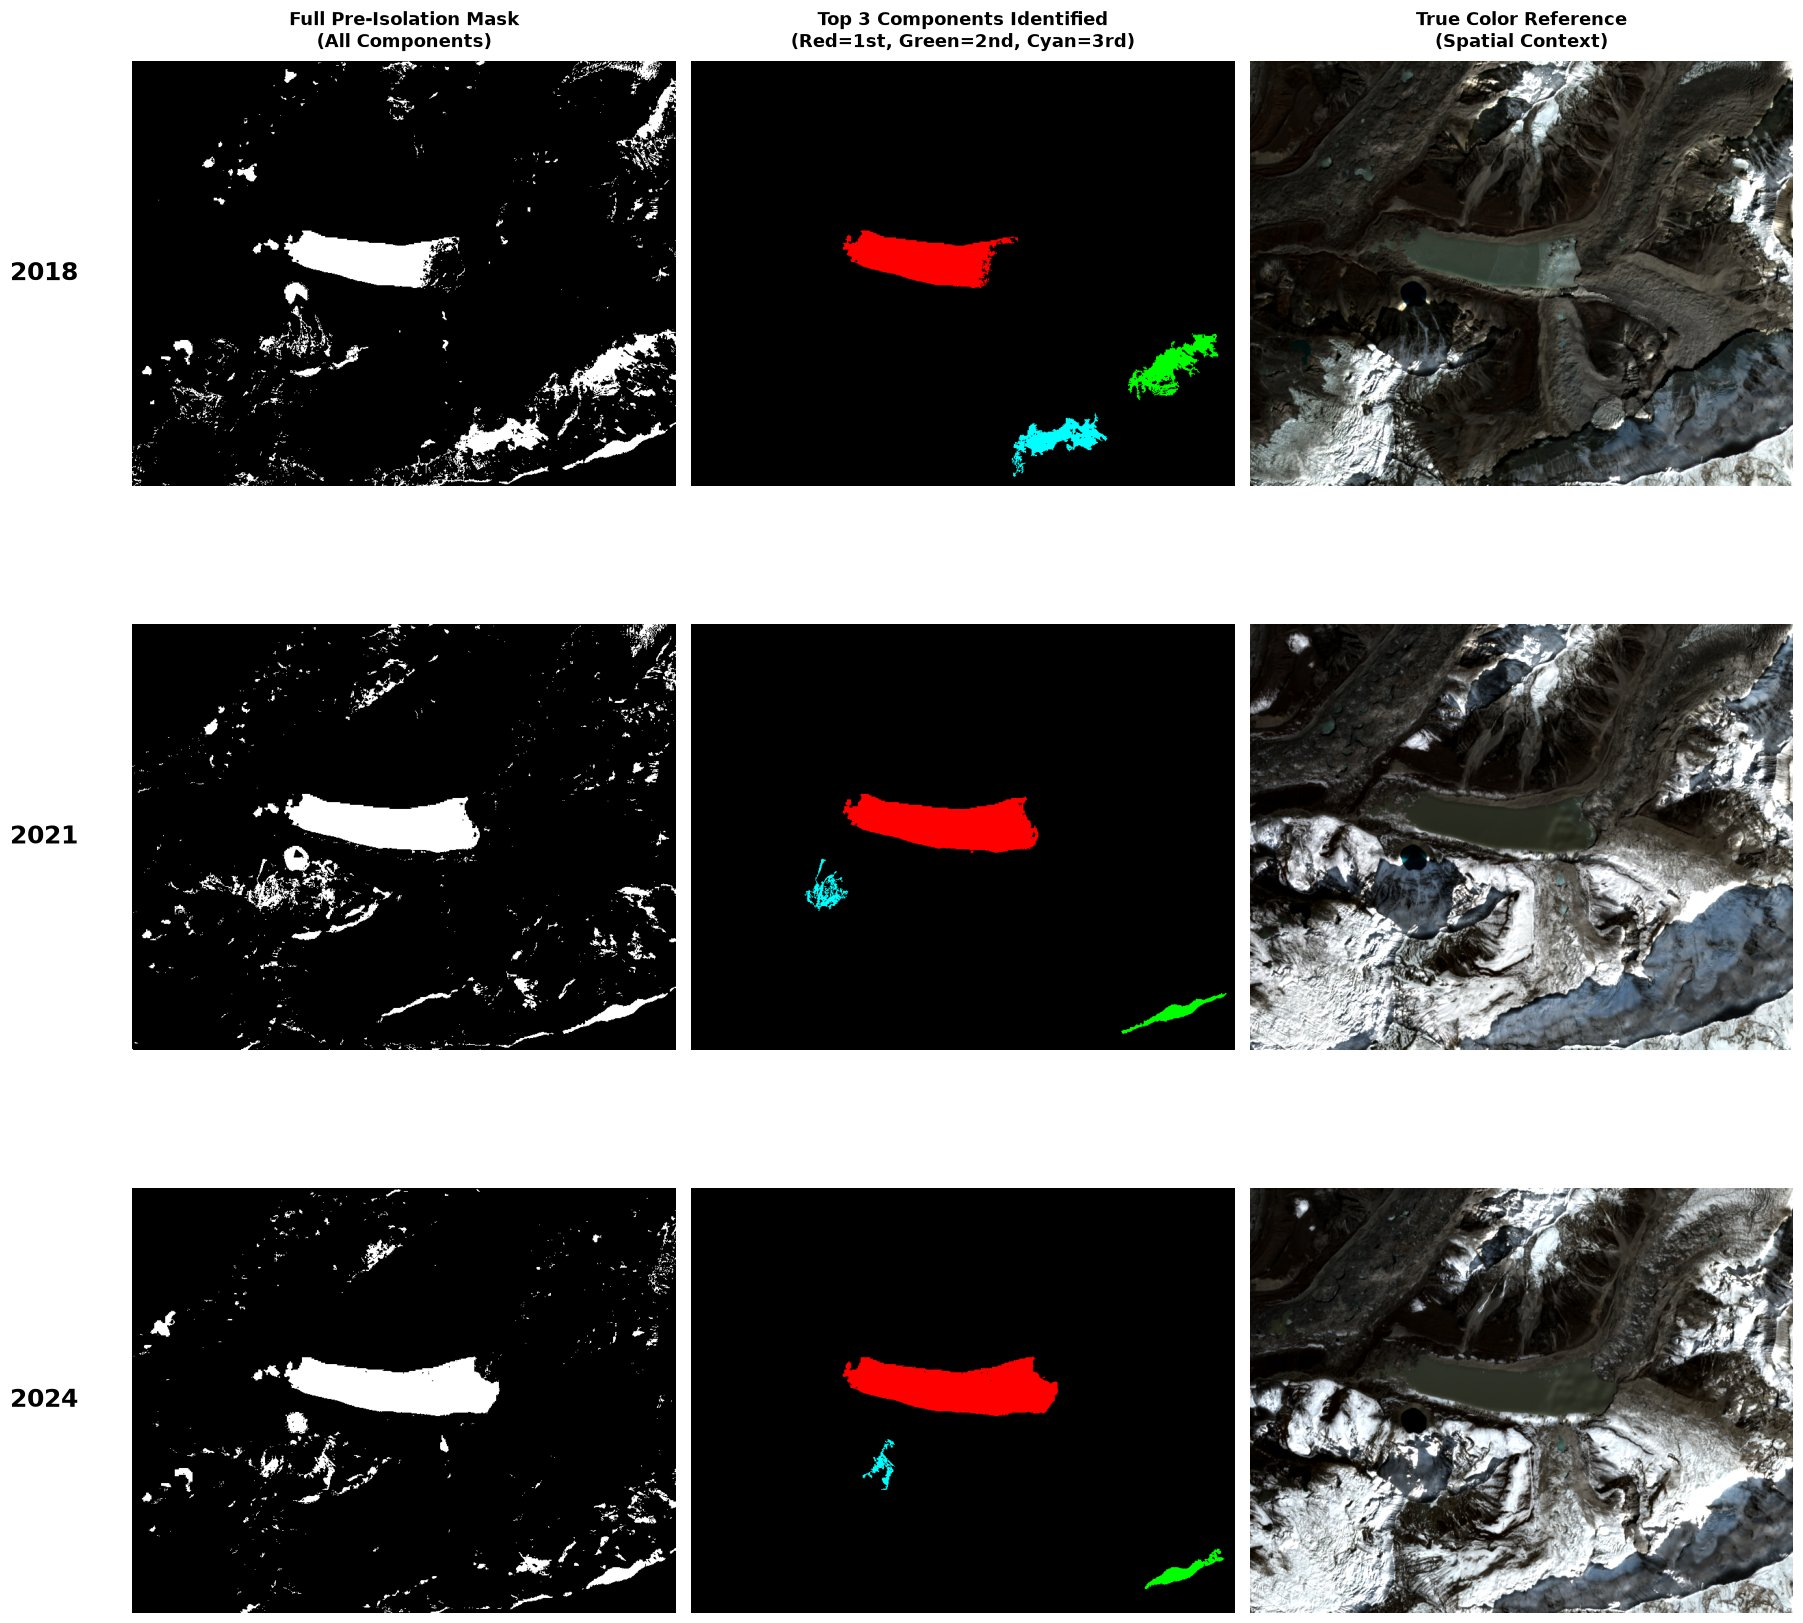

In [15]:
fig = plotting.plot_fragmentation(detections)

### Boundary uncertainty

At 10 m resolution, pixels along the shoreline are mixtures of water and land, and any of them could be misclassified. The uncertainty below counts one whole pixel (100 m²) for every vertex of the lake's outline, including the outlines of holes inside the lake. Each vertex marks one pixel edge between water and land. This is a deliberately conservative bound, about 2.5 times the common convention of half a pixel along the perimeter, which is shown for comparison.

The uncertainty of each change combines the two dates' uncertainties in quadrature. Both cover shoreline error only, not the choice of thresholds, which is tested in the next section.

In [16]:
for year, det in detections.items():
    n_vertices = metrics.boundary_vertex_count(det.lake_mask)
    half_pixel = perimeter(det.lake_mask) * pixel_width * (pixel_width / 2) / 1e6
    print(
        f"{year}: {det.area_km2:.3f} ± {uncertainties[year]:.3f} km² "
        f"({n_vertices} contour vertices; half-pixel convention ± {half_pixel:.3f} km²)"
    )

print()
for change in metrics.area_changes(areas, uncertainties):
    print(
        f"{change.start}–{change.end}: {change.absolute_km2:+.3f} ± "
        f"{change.uncertainty_km2:.3f} km²"
    )

2018: 1.179 ± 0.118 km² (1180 contour vertices; half-pixel convention ± 0.046 km²)
2021: 1.571 ± 0.098 km² (983 contour vertices; half-pixel convention ± 0.044 km²)
2024: 1.792 ± 0.104 km² (1040 contour vertices; half-pixel convention ± 0.045 km²)

2018–2021: +0.393 ± 0.154 km²
2021–2024: +0.221 ± 0.143 km²
2018–2024: +0.614 ± 0.157 km²


### Sensitivity to the thresholds

Two thresholds could drive the results: the NIR ceiling, chosen by hand, and the MNDWI Otsu threshold, computed separately for each date. The first table repeats the detection with NIR ceilings from 0.15 to 0.25. The second applies one Otsu threshold pooled over all three dates.

In [17]:
first, last = target_years[0], target_years[-1]
header = "".join(f"{year:>8}" for year in target_years)
print(f"NIR ceiling |{header} | {first}–{last} | per year")
for ceiling in np.round(np.arange(0.15, 0.251, 0.01), 2):
    a = {year: detect_lake(scene, nir_ceiling=ceiling).area_km2 for year, scene in scenes.items()}
    total = metrics.area_changes(a)[-1].percent
    rate = metrics.compound_annual_growth_rate(a, ACQUISITION_DATES)
    used = "  <- used" if np.isclose(ceiling, NIR_CEILING) else ""
    row = "".join(f"{a[year]:>8.3f}" for year in target_years)
    print(f"{ceiling:>11.2f} |{row} | {total:>+8.1f}% | {rate:>7.2%}{used}")

NIR ceiling |    2018    2021    2024 | 2018–2024 | per year
       0.15 |   1.098   1.465   1.681 |    +53.0% |   7.41%
       0.16 |   1.125   1.506   1.738 |    +54.5% |   7.58%
       0.17 |   1.139   1.534   1.763 |    +54.8% |   7.61%
       0.18 |   1.151   1.550   1.777 |    +54.4% |   7.57%
       0.19 |   1.163   1.561   1.785 |    +53.5% |   7.46%
       0.20 |   1.179   1.571   1.792 |    +52.1% |   7.29%  <- used


       0.21 |   1.210   1.580   1.798 |    +48.6% |   6.88%


       0.22 |   1.241   1.589   1.803 |    +45.3% |   6.47%
       0.23 |   1.265   1.594   1.806 |    +42.7% |   6.15%
       0.24 |   1.295   1.598   1.810 |    +39.7% |   5.78%
       0.25 |   1.317   1.603   1.817 |    +37.9% |   5.55%


In [18]:
pooled = threshold_otsu(
    np.concatenate([det.mndwi[det.scene.valid_mask] for det in detections.values()])
)
print(f"MNDWI Otsu threshold pooled over all dates: {pooled:.4f}")
for year, scene in scenes.items():
    pooled_area = detect_lake(scene, mndwi_threshold=pooled).area_km2
    print(
        f"  {year}: {areas[year]:.3f} km² with its own threshold "
        f"({detections[year].otsu_threshold:.4f}), {pooled_area:.3f} km² with the pooled one"
    )

MNDWI Otsu threshold pooled over all dates: 0.2461
  2018: 1.179 km² with its own threshold (0.2275), 1.177 km² with the pooled one
  2021: 1.571 km² with its own threshold (0.2695), 1.573 km² with the pooled one
  2024: 1.792 km² with its own threshold (0.2517), 1.793 km² with the pooled one


The NIR ceiling matters, and most of all in 2018. The lake's own NIR distribution reaches the ceiling (its brightest pixels are just under 0.20), and the 2018 ice margin contains many pixels just above it. Between 0.15 and 0.25 the 2018 area ranges from 1.10 to 1.32 km², and growth over 2018–2024 from +38% to +55% (5.5–7.6% per year). On the trend, this is a larger effect than the shoreline uncertainty.

The per-date Otsu thresholds, by contrast, do not drive the trend: a single threshold pooled over all dates changes no area by more than 0.002 km².

### How much of the lake was ice-covered?

In 2018 the eastern part of the lake is covered by ice (see the shoreline figures above). These pixels are dark in the shortwave infrared, like the water around them, but bright in the visible and near-infrared, so the NIR test classifies them as snow or ice rather than open water. Pixels that were snow or ice on one date and open water on a later one estimate how much of the lake was ice-covered. Adding them to the 2018 open water gives an approximate total lake area for 2018, and with it the growth of the lake itself rather than of its open water.

In [19]:
ice_km2 = {}
for i, year in enumerate(target_years[:-1]):
    later_lakes = np.logical_or.reduce([detections[y].lake_mask for y in target_years[i + 1 :]])
    ice = detections[year].snow_ice_mask & later_lakes
    ice_km2[year] = metrics.area_km2(ice, detections[year].scene.pixel_area_m2)
    print(f"{year}: {ice_km2[year]:.3f} km² was snow or ice, but open water on a later date")

with_ice = {first: areas[first] + ice_km2[first], last: areas[last]}
growth = metrics.area_changes(with_ice)[0]
rate = metrics.compound_annual_growth_rate(with_ice, ACQUISITION_DATES)
print(
    f"\n{first} open water plus that ice: {with_ice[first]:.3f} km². Growth to {last}: "
    f"{growth.absolute_km2:+.3f} km² ({growth.percent:+.1f}%), {rate:.2%} per year"
)

previous = target_years[-2]
last_interval = {previous: areas[previous], last: areas[last]}
growth = metrics.area_changes(last_interval)[0]
rate = metrics.compound_annual_growth_rate(last_interval, ACQUISITION_DATES)
print(
    f"{previous}–{last} open water: {growth.absolute_km2:+.3f} km² ({growth.percent:+.1f}%), "
    f"{rate:.2%} per year"
)

2018: 0.277 km² was snow or ice, but open water on a later date
2021: 0.065 km² was snow or ice, but open water on a later date

2018 open water plus that ice: 1.455 km². Growth to 2024: +0.337 km² (+23.1%), 3.56% per year
2021–2024 open water: +0.221 km² (+14.0%), 4.59% per year


## 6. Conclusions

### Findings

The open-water area of Imja Tsho was **1.179 ± 0.118 km²** on 30 October 2018, **1.571 ± 0.098 km²** on 8 November 2021 and **1.792 ± 0.104 km²** on 13 October 2024. Open water grew by 0.393 ± 0.154 km² (+33.4%) between 2018 and 2021 and by 0.221 ± 0.143 km² (+14.0%) between 2021 and 2024: **0.614 ± 0.157 km² (+52.1%) overall**, or about 7.3% per year over the 5.95 years between the acquisitions.

That headline figure overstates the growth of the lake itself, because much of the lake was ice-covered in 2018. Counting the 2018 ice that later became open water, the lake grew by about **0.34 km² (+23%, 3.6% per year)** between 2018 and 2024. The 2021–2024 interval, with much less ice, gives a similar rate: +14.0%, or **4.6% per year**.

Nearly all of the change is at the eastern, glacier end of the lake. The westernmost point, at the outlet, did not move, and over 90% of the gained pixels lie in the eastern half. The eastern shore advanced by about 300 m in each three-year interval, consistent with the glacier front retreating as it loses ice into the lake.

### Open water versus total lake area

The 2018 lake ice is dark in the shortwave infrared like water, but bright in the visible and near-infrared, so the NIR test correctly excludes it as not open water. About 0.28 km² of 2018 snow or ice became open water by 2021 or 2024, roughly 70% of the 2018–2021 increase. The estimate is approximate: it may include some snow along the shore, and it misses any ice still present in 2024. In 2021 the same measure gives 0.065 km², about 30% of the 2021–2024 increase, so that interval is the cleaner estimate but not a completely ice-free one. The reported areas should be read as *open-water area at the time of acquisition*.

### Method notes

- **Snow rejection.** MNDWI cannot tell water from snow, because it uses the same formula as the snow index NDSI. A near-infrared reflectance ceiling (B08 < 0.20) separates them, because liquid water absorbs NIR. The value is empirical: a stricter 0.15 starts to cut into the sediment plumes in the lake, whose NIR reflectance is around 0.12–0.15.
- **Connected components.** Even after snow rejection, the water mask contains hundreds of small separate patches. Keeping the largest connected component isolates the lake reliably, and the nesting and fragmentation checks confirm that it is the same, intact lake on every date.

### Limitations

- **NIR ceiling.** The 0.20 ceiling is a single empirical value, and the results depend on it: between 0.15 and 0.25, growth over 2018–2024 ranges from +38% to +55%. Lake water with very high sediment content, or thin ice and slush, can fall on either side of it.
- **Season.** The acquisitions span mid-October to early November, so the extent of lake ice and snow differs between dates, most visibly in 2018.
- **Shadows.** Steep terrain casts deep shadows in which all reflectances approach zero and the normalised-difference indices become unstable. These pixels can show extreme index values, but they lie away from the lake and are removed by the largest-component step.
- **Resolution.** At 10 m, shoreline pixels are mixed. The boundary uncertainty is a deliberately conservative bound and covers shoreline error only.
- **Per-date thresholds** are *not* a significant limitation: a single Otsu threshold pooled over all dates changes no area by more than 0.002 km².

### Relevance for GLOF hazard

A larger lake behind the same moraine dam means more water that could be released in an outburst flood. Depending on how the 2018 ice is treated, the lake grew by 3.6–7.3% per year, with the ice-corrected and 2021–2024 estimates (3.6% and 4.6%) the more representative. The growth is concentrated at the glacier end, consistent with continued glacier retreat into the lake. The pipeline is automatic apart from the choice of dates, so applying it to more acquisitions, chosen when the lake is free of ice, would give a monitoring record of the expansion rate itself.

## References

- Hall, D. K., Riggs, G. A., & Salomonson, V. V. (1995). Development of methods for mapping global snow cover using moderate resolution imaging spectroradiometer data. *Remote Sensing of Environment*, 54(2), 127–140.
- McFeeters, S. K. (1996). The use of the Normalized Difference Water Index (NDWI) in the delineation of open water features. *International Journal of Remote Sensing*, 17(7), 1425–1432.
- Otsu, N. (1979). A threshold selection method from gray-level histograms. *IEEE Transactions on Systems, Man, and Cybernetics*, 9(1), 62–66.
- Xu, H. (2006). Modification of normalised difference water index (NDWI) to enhance open water features in remotely sensed imagery. *International Journal of Remote Sensing*, 27(14), 3025–3033.
- Contains modified Copernicus Sentinel data (2018, 2021, 2024), processed by the Copernicus Data Space Ecosystem.